# Bank Data Analysis

# Objective

In this case study, you will be working on Banking Data Analysis using Apache Spark, a powerful distributed computing framework designed for big data processing. This assignment aims to give you hands-on experience in analyzing large-scale banking datasets using PySpark and AWS services. You will apply techniques learned in data analytics to clean, transform, and explore banking data, drawing meaningful insights to support financial decision-making. Apart from understanding how big data tools can optimize performance on a single machine and across clusters, you will develop a structured approach to analyzing market capitalization trends, currency conversions, and global banking performance. Additionally, you will use AWS S3 to store the processed data once the ETL pipeline is complete, ensuring efficient data management and retrieval.


# Business Value

The banking industry operates in a highly competitive and globalized market where financial institutions must continuously monitor their market position, performance, and currency fluctuations. To stay competitive, banks must leverage data-driven insights to optimize their financial strategies, assess market trends, and make informed decisions. In this assignment, you will analyze banking data to uncover patterns in market capitalization, currency conversions, and global rankings. With Apache Spark's ability to handle large datasets efficiently, financial institutions can process vast amounts of data in real-time, helping them make faster and more informed decisions.


As an analyst at a financial institution, your task is to examine historical banking data to derive actionable insights that can drive strategic growth. Your analysis will help identify the top 10 largest banks by market capitalization, convert market cap values into multiple currencies (USD, GBP, EUR, INR), and store the processed data for easy retrieval. To enhance scalability and accessibility, you will utilize AWS S3 for data storage, ensuring seamless integration with cloud-based analytics tools. By leveraging big data analytics and cloud services, financial institutions can streamline operations, enhance decision-making, and maximize revenue opportunities.


# Dataset

The data for this project can be accessed from the following [wikipedia link](https://web.archive.org/web/20230908091635/https://en.wikipedia.org/wiki/List_of_largest_banks).

The dataset used in this analysis comprises global banking data extracted from a Wikipedia page (List of Largest Banks) archived as of September 2023.

It includes rankings of the world's largest banks based on market capitalization (in USD billions) and is structured into a single table with three columns. The data was scraped programmatically, cleaned, and transformed using PySpark to support cross-currency analysis. Exchange rate data (for USD, GBP, EUR, and INR) was sourced from a CSV file to enable currency conversions. The processed dataset is stored in CSV and SQLite formats for accessibility and efficient querying.

The dataset consists of a single table (Largest_banks) with the following three key attributes:
- **Rank:** Numerical position of the bank based on market capitalization.
- **Bank Name:** Name of the financial institution.
- **Market Cap (USD Billion):** Market valuation of the bank in USD billions.
This dataset enables analysis of global banking trends, cross-currency valuations, and the relative market dominance of financial institutions.

An additional data on market exchange rates is available to compare the marketcap dealing with different currencies.


<h2>Assignment Tasks</h2>

<ol>
    <li>
        <strong>Data Preparation</strong>
        <p>The dataset consists of a structured table containing global banking data. Before performing any analysis, it is crucial to prepare the data to ensure consistency and efficiency in processing.</p>
        Check for data consistency and ensure all columns are correctly formatted.<br>
        Structure and prepare the data for further processing and analysis.<br>
</br>
    <li>
        <strong>Data Cleaning</strong>
        <ul>
            2.1. <strong>Handling Missing Values:</strong> Decide on an approach to handle missing data (e.g., imputation or removal). Mention the approach in your report.<br>
            2.2. <strong>Fixing Columns:</strong> Ensure all columns are properly named and formatted.<br>
            2.3. <strong>Handling Outliers:</strong> Identify outliers in the dataset and explain why they are considered outliers. It is not necessary to remove them for this task, but mention your approach for handling them.<br>
        </ul>
</br>
    <li>
        <strong>Exploratory Data Analysis:</strong></br>
            EDA Finding Patterns - Analyze the dataset and find patterns based on the following points:
                <ul>
                    3.1. Convert PySpark DataFrame to Pandas DataFrame for visualization.<br>
                    3.2. Analyze the distribution of market capitalization using a histogram.<br>
                    3.3. Identify the top 10 banks by market capitalization using a bar chart.<br>
                    3.4. Visualize the relationship between market capitalization and bank ranking using a scatter plot.<br>
                    3.5. Use a boxplot to examine the spread and outliers in market capitalization.<br>
                    3.6. Display the quartile distribution of market capitalization using a violin plot.<br>
                    3.7. Compute cumulative market share and visualize it with a line plot.<br>
                    3.8. Categorize banks into market capitalization ranges and analyze their distribution using a bar chart.<br>
                    3.9. Calculate and display market share distribution of top 10 banks using a pie chart.<br>
                </ul>
        </ul>
</br>
    <li>
        <strong>Banking Data ETL Querying</strong>
        <ul>
            4.1. Perform Advanced Market Capitalization Analysis with Growth Metrics.<br>
            4.2. Analyze Market Concentration and Categorize Banks Based on Market Share Tiers.<br>
            4.3. Examine Statistical Distribution of Market Capitalization Using Quartile Analysis.<br>
            4.4. Conduct Comparative Size Analysis to Classify Banks by Relative Market Size.<br>
            4.5. Evaluate Market Growth and Identify Gaps Between Consecutive Banks.<br>
            4.6. Assess Market Dominance by Measuring Cumulative Share and Dominance Score.<br>
            4.7. Analyze Segment-Wise Bank Performance Based on Market Capitalization Ranges.<br>
            4.8. Generate a Comprehensive Performance Dashboard for Bank Rankings and Metrics.<br>
        </ul>
    </br>
    <li>
        <strong>Conclusion</strong></br>
            Provide final insights and recommendations based on the analysis:</br>
            <ul>
            5.1 Recommendations to track and compare market capitalisation of the top global banks toevaluate competitiveness and dominance.</br>
            5.2 Suggestions to use cross-currency analysis (USD, GBP, EUR, INR) for consistent benchmarking
of financial institutions across regions.</br>
            5.3 Propose continuous monitoring of market share concentration to identify growth opportunities
for mid-tier banks.</br>
            5.4  Identify potential regions or banking segments for expansion by analysing gaps between tiers
of banks and regional trends.</br>
            </ul>
    </br>
    <li>
        <strong>Visualization Integration [Optional]</strong>
        <p>Enhance the project by incorporating a visualization component that connects the processed data stored in an S3 bucket to a business intelligence tool such as Tableau or Power BI. This involves setting up the connection between the S3 bucket and the chosen visualization tool, importing the processed dataset for analysis and visualization, creating interactive dashboards to explore key trends and insights and ensuring data updates are reflected dynamically in the visualization tool.<br>
        </ul>
</ol>

Import Required Libraries

In [1]:
# # Install the required libraries
# !pip install --quiet pyspark==3.5.4 pandas==2.2.2

In [2]:
# Import required libraries
import logging
import sqlite3
import requests
from io import StringIO
from datetime import datetime

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Import PySpark libraries
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, round, count, when, isnull

In [3]:
# Initialize Spark session
spark = SparkSession.builder \
    .appName("BankingDataAnalysis") \
    .getOrCreate()

#**1. Data Preparation** <font color = red>[5 marks]</font> <br>


The data for this project can be accessed from the wikipedia link provided above. The page features data regarding global banking data.

Utilise the pandas method to read tables from the html document
and extract the requried data consists of a structured format.

Before performing any analysis, it is crucial to prepare the data to ensure consistency, and efficiency in processing.

In [4]:
# Initialize Spark session
spark = SparkSession.builder.appName("BankingDataAnalysis").getOrCreate()

# URL of the Wikipedia page
url = "https://web.archive.org/web/20230908091635/https://en.wikipedia.org/wiki/List_of_largest_banks"

# Use pandas to read all HTML tables from the page
import requests
from io import StringIO
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text
tables = pd.read_html(StringIO(html))
print("Tables found:", len(tables))
for i, t in enumerate(tables):
    print(i, t.shape, list(t.columns)[:4])   # helps you spot the right table

# Load the correct table (Table 1)
# the market-cap table = the one with 3 columns incl. "Market cap"
df_pd = next(t for t in tables if any("market cap" in str(c).lower() for c in t.columns))

# Convert pandas DataFrame to PySpark DataFrame
df = spark.createDataFrame(df_pd)

# Rename columns
df = df.toDF("Rank", "Bank_Name", "Market_Cap_USD_Billion")

# Show the first few rows of the PySpark DataFrame
df.show(truncate=False)

# Print the schema of the DataFrame
df.printSchema()

# Configure logging
logging.basicConfig(filename="code_log.txt", level=logging.INFO,
                    format="%(asctime)s - %(message)s")
logging.info("Wikipedia bank table loaded into Spark DataFrame")

Tables found: 3
0 (10, 3) ['Rank', 'Bank name', 'Market cap (US$ billion)']
1 (100, 3) ['Rank', 'Bank name', 'Total assets (2022) (US$ billion)']
2 (25, 3) ['Rank', 'Country', 'Number']
+----+---------------------------------------+----------------------+
|Rank|Bank_Name                              |Market_Cap_USD_Billion|
+----+---------------------------------------+----------------------+
|1   |JPMorgan Chase                         |432.92                |
|2   |Bank of America                        |231.52                |
|3   |Industrial and Commercial Bank of China|194.56                |
|4   |Agricultural Bank of China             |160.68                |
|5   |HDFC Bank                              |157.91                |
|6   |Wells Fargo                            |155.87                |
|7   |HSBC Holdings PLC                      |148.9                 |
|8   |Morgan Stanley                         |140.83                |
|9   |China Construction Bank               

Load the data for exchange rates

In [5]:

# Load the exchange rate data
exchange_df = spark.read.csv("D:/downloads/exchange_rate(in).csv", header=True, inferSchema=True)

# Show the first few rows of the exchange rate data to verify
exchange_df.show()
exchange_df.printSchema()



+--------+-----+
|Currency| Rate|
+--------+-----+
|     EUR| 0.93|
|     GBP|  0.8|
|     INR|82.95|
+--------+-----+

root
 |-- Currency: string (nullable = true)
 |-- Rate: double (nullable = true)



#**2. Data Cleaning** <font color = red>[20 marks]</font> <br>

##**2.1 Handle Missing Values** <font color = red>[10 marks]</font> <br>


In [6]:
# Print the schema to check data types
df.printSchema()

root
 |-- Rank: long (nullable = true)
 |-- Bank_Name: string (nullable = true)
 |-- Market_Cap_USD_Billion: double (nullable = true)



In [7]:
# Check for missing values
df.select([count(when(isnull(col(c)), c)).alias(c) for c in df.columns]).show()

+----+---------+----------------------+
|Rank|Bank_Name|Market_Cap_USD_Billion|
+----+---------+----------------------+
|   0|        0|                     0|
+----+---------+----------------------+



In [8]:
# Drop rows with missing values
rows_before = df.count()
df_clean = df.dropna()
rows_after = df_clean.count()
print(f"Rows before: {rows_before}, after: {rows_after}, dropped: {rows_before - rows_after}")
df_clean.show(truncate=False)

Rows before: 10, after: 10, dropped: 0
+----+---------------------------------------+----------------------+
|Rank|Bank_Name                              |Market_Cap_USD_Billion|
+----+---------------------------------------+----------------------+
|1   |JPMorgan Chase                         |432.92                |
|2   |Bank of America                        |231.52                |
|3   |Industrial and Commercial Bank of China|194.56                |
|4   |Agricultural Bank of China             |160.68                |
|5   |HDFC Bank                              |157.91                |
|6   |Wells Fargo                            |155.87                |
|7   |HSBC Holdings PLC                      |148.9                 |
|8   |Morgan Stanley                         |140.83                |
|9   |China Construction Bank                |139.82                |
|10  |Bank of China                          |136.81                |
+----+---------------------------------------+-----

##**2.2 Fixing Columns** <font color = red>[5 marks]</font> <br>


The Market cap is already in numeric so no conversion needed.

In [9]:
from pyspark.sql.functions import trim

# Count the total number of rows
# (also trim stray spaces in bank names, a harmless safeguard)
df_clean = df_clean.withColumn("Bank_Name", trim(col("Bank_Name")))
total_rows = df_clean.count()
print("Total rows:", total_rows)

# Check if there are duplicates
dup_rows = total_rows - df_clean.dropDuplicates().count()
dup_names = total_rows - df_clean.select("Bank_Name").distinct().count()
print("Duplicate rows:", dup_rows)
print("Duplicate bank names:", dup_names)

Total rows: 10
Duplicate rows: 0
Duplicate bank names: 0


##**2.2 Handle Outliers** <font color = red>[5 marks]</font> <br>


In [10]:
# Write code for outlier analysis
mc = df_clean.select("Bank_Name", "Market_Cap_USD_Billion").toPandas()
x = mc["Market_Cap_USD_Billion"]

# IQR method
q1, q3 = x.quantile(0.25), x.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"Lower fence={lower:.2f}, Upper fence={upper:.2f}")

mc["Is_Outlier_IQR"] = (x < lower) | (x > upper)

# Z-score cross-check
mc["Z_Score"] = ((x - x.mean()) / x.std()).round(2)

print(mc.sort_values("Market_Cap_USD_Billion", ascending=False))
print("Outliers:", mc.loc[mc["Is_Outlier_IQR"], "Bank_Name"].tolist())

Q1=142.85, Q3=186.09, IQR=43.24
Lower fence=77.98, Upper fence=250.95
                                 Bank_Name  Market_Cap_USD_Billion  \
0                           JPMorgan Chase                  432.92   
1                          Bank of America                  231.52   
2  Industrial and Commercial Bank of China                  194.56   
3               Agricultural Bank of China                  160.68   
4                                HDFC Bank                  157.91   
5                              Wells Fargo                  155.87   
6                        HSBC Holdings PLC                  148.90   
7                           Morgan Stanley                  140.83   
8                  China Construction Bank                  139.82   
9                            Bank of China                  136.81   

   Is_Outlier_IQR  Z_Score  
0            True     2.69  
1           False     0.46  
2           False     0.05  
3           False    -0.32  
4           Fa

Saving the Cleaned Dataset into a CSV File into the S3 Bucket


In [11]:
# Save the cleaned dataset as a CSV file (local copy; S3 not configured)
clean_pd = df_clean.toPandas()
clean_pd.to_csv("cleaned_banks.csv", index=False)
print("Saved cleaned_banks.csv with", len(clean_pd), "rows")

Saved cleaned_banks.csv with 10 rows


#**3. Exploratory Data Analysis** <font color = red>[40 marks]</font> <br>


##**3.1. Conversion from PySpark to Pandas DataFrame** <font color = red>[5 marks]</font> <br>

Convert PySpark DataFrame to Pandas DataFrame for visualization

In [12]:

# Convert PySpark DataFrame to Pandas DataFrame
bank_pdf = df_clean.toPandas()

bank_pdf.info()
bank_pdf.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Rank                    10 non-null     int64  
 1   Bank_Name               10 non-null     object 
 2   Market_Cap_USD_Billion  10 non-null     float64
dtypes: float64(1), int64(1), object(1)
memory usage: 372.0+ bytes


,Rank,Bank_Name,Market_Cap_USD_Billion
0,1,JPMorgan Chase,432.92
1,2,Bank of America,231.52
2,3,Industrial and Commercial Bank of China,194.56
3,4,Agricultural Bank of China,160.68
4,5,HDFC Bank,157.91
5,6,Wells Fargo,155.87
6,7,HSBC Holdings PLC,148.90
7,8,Morgan Stanley,140.83
8,9,China Construction Bank,139.82
9,10,Bank of China,136.81


##**3.2. Market Capitalization** <font color = red>[5 marks]</font> <br>

Analyze the distribution of market capitalization using a histogram

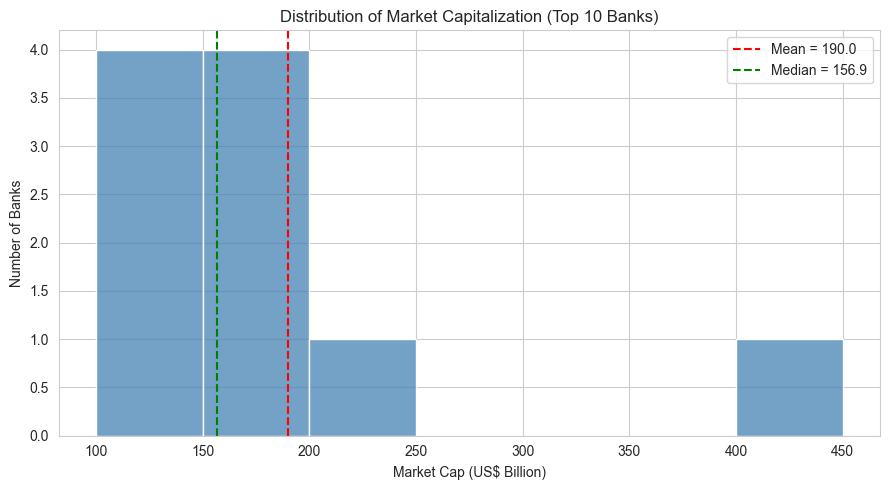

In [13]:
# Distribution of Market Cap (US$ Billion)
mean_cap = bank_pdf["Market_Cap_USD_Billion"].mean()
median_cap = bank_pdf["Market_Cap_USD_Billion"].median()

# Set the style for seaborn
sns.set_style("whitegrid")

# Plot the distribution of market cap
plt.figure(figsize=(9, 5))
sns.histplot(bank_pdf["Market_Cap_USD_Billion"], bins=range(100, 500, 50),
             color="steelblue", edgecolor="white")
plt.axvline(mean_cap, color="red", linestyle="--", label=f"Mean = {mean_cap:.1f}")
plt.axvline(median_cap, color="green", linestyle="--", label=f"Median = {median_cap:.1f}")
plt.title("Distribution of Market Capitalization (Top 10 Banks)")
plt.xlabel("Market Cap (US$ Billion)")
plt.ylabel("Number of Banks")
plt.legend()
plt.tight_layout()
plt.show()

##**3.3. Top 10 Banks** <font color = red>[5 Marks]</font> <br>

Identify the top 10 banks by market capitalization using a bar chart

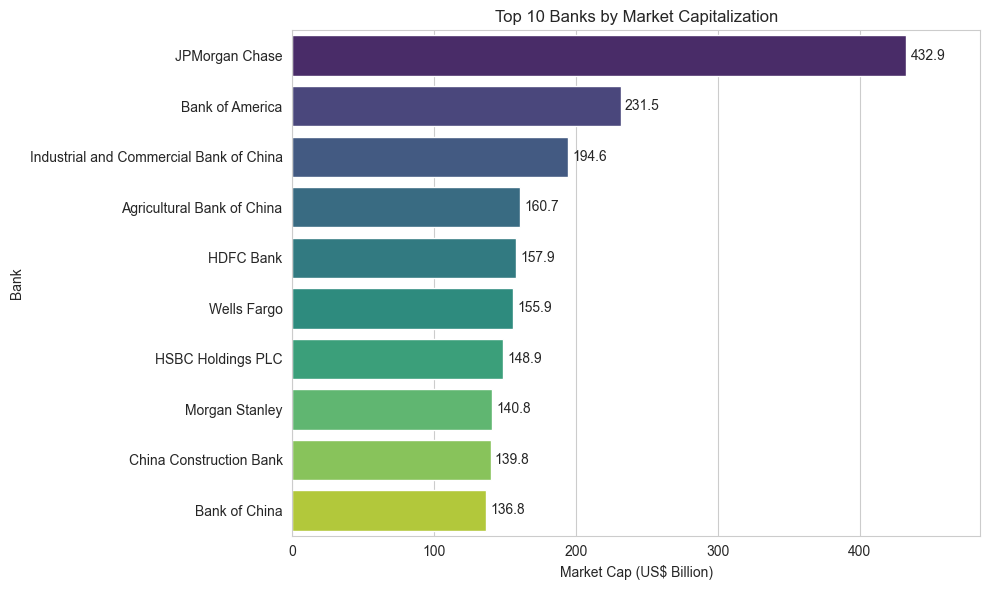

In [14]:
# Top 10 Banks by Market Cap

# Sort the DataFrame by market cap in descending order
top10 = bank_pdf.sort_values("Market_Cap_USD_Billion", ascending=False).head(10)

# Plot the top 10 banks by market cap
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=top10, x="Market_Cap_USD_Billion", y="Bank_Name",
                 hue="Bank_Name", palette="viridis", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
plt.title("Top 10 Banks by Market Capitalization")
plt.xlabel("Market Cap (US$ Billion)")
plt.ylabel("Bank")
plt.xlim(0, top10["Market_Cap_USD_Billion"].max() * 1.12)
plt.tight_layout()
plt.show()

##**3.4. Market Cap vs Bank Ranking** <font color = red>[5 Marks]</font> <br>

Visualize the relationship between market capitalization and bank ranking using a scatter plot

<function matplotlib.pyplot.xlim(*args, **kwargs) -> 'tuple[float, float]'>

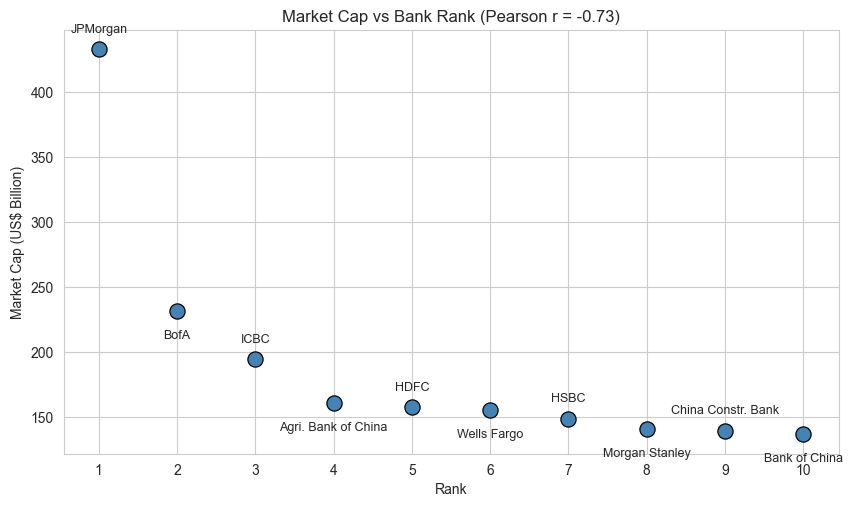

In [15]:
# Market Cap vs Rank
corr = bank_pdf["Rank"].corr(bank_pdf["Market_Cap_USD_Billion"])

# Short names so the labels fit
short_names = {
    "JPMorgan Chase": "JPMorgan",
    "Bank of America": "BofA",
    "Industrial and Commercial Bank of China": "ICBC",
    "Agricultural Bank of China": "Agri. Bank of China",
    "HDFC Bank": "HDFC",
    "Wells Fargo": "Wells Fargo",
    "HSBC Holdings PLC": "HSBC",
    "Morgan Stanley": "Morgan Stanley",
    "China Construction Bank": "China Constr. Bank",
    "Bank of China": "Bank of China",
}

# Plot market cap vs rank
plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=bank_pdf, x="Rank", y="Market_Cap_USD_Billion",
                s=120, color="steelblue", edgecolor="black")
for i, row in bank_pdf.iterrows():
    label = short_names.get(row["Bank_Name"], row["Bank_Name"])
    offset = (0, 12) if i % 2 == 0 else (0, -20)      # alternate above / below
    plt.annotate(label, (row["Rank"], row["Market_Cap_USD_Billion"]),
                 textcoords="offset points", xytext=offset,
                 ha="center", fontsize=9)
plt.title(f"Market Cap vs Bank Rank (Pearson r = {corr:.2f})")
plt.xlabel("Rank")
plt.ylabel("Market Cap (US$ Billion)")
plt.xticks(range(1, 11))
plt.xlim

##**3.5. Market Cap Analysis** <font color = red>[5 Marks]</font> <br>

Use a boxplot to examine the spread and outliers in market capitalization.

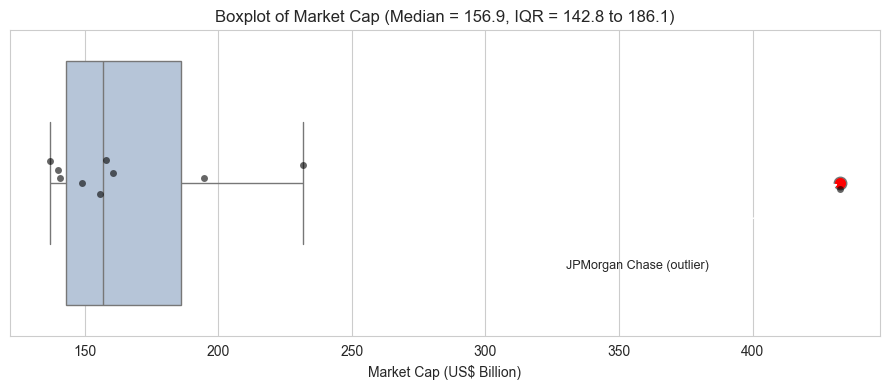

In [16]:
# Boxplot of Market Cap
#To show the spread and outliers in the market capitalization data.
q1 = bank_pdf["Market_Cap_USD_Billion"].quantile(0.25)
med = bank_pdf["Market_Cap_USD_Billion"].median()
q3 = bank_pdf["Market_Cap_USD_Billion"].quantile(0.75)

# Plot a boxplot of market cap
plt.figure(figsize=(9, 4))
sns.boxplot(x=bank_pdf["Market_Cap_USD_Billion"], color="lightsteelblue",
            flierprops=dict(marker="o", markerfacecolor="red", markersize=9))
sns.stripplot(x=bank_pdf["Market_Cap_USD_Billion"], color="black", size=5, alpha=0.6)
plt.annotate("JPMorgan Chase (outlier)", xy=(432.92, 0), xytext=(330, 0.28),
             arrowprops=dict(arrowstyle="->"), fontsize=9)
plt.title(f"Boxplot of Market Cap (Median = {med:.1f}, IQR = {q1:.1f} to {q3:.1f})")
plt.xlabel("Market Cap (US$ Billion)")
plt.tight_layout()
plt.show()

##**3.6. Market Cap Quartile Distribution** <font color = red>[5 Marks]</font> <br>

Display the quartile distribution of market capitalization using a violin plot.

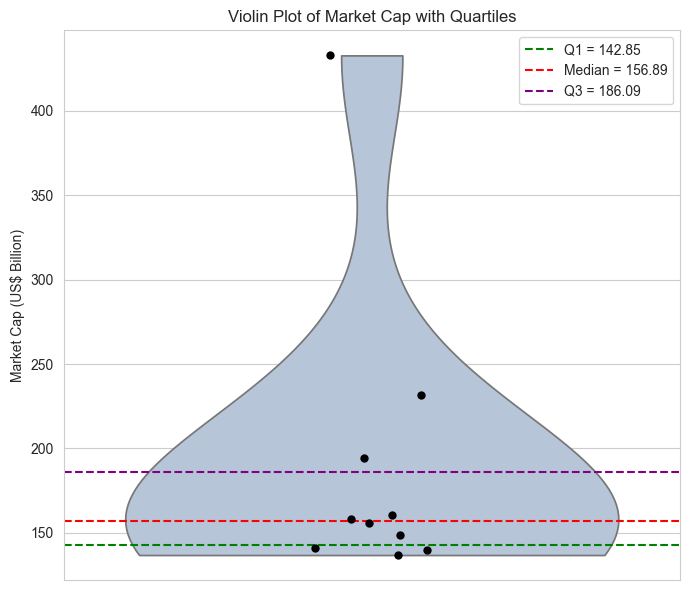

In [17]:
# Market Cap Distribution by Quartile
q1 = bank_pdf["Market_Cap_USD_Billion"].quantile(0.25)
med = bank_pdf["Market_Cap_USD_Billion"].median()
q3 = bank_pdf["Market_Cap_USD_Billion"].quantile(0.75)

plt.figure(figsize=(7, 6))
sns.violinplot(y=bank_pdf["Market_Cap_USD_Billion"], inner=None,
               color="lightsteelblue", cut=0)
sns.stripplot(y=bank_pdf["Market_Cap_USD_Billion"], color="black", size=6)
plt.axhline(q1, color="green", linestyle="--", label=f"Q1 = {q1:.2f}")
plt.axhline(med, color="red", linestyle="--", label=f"Median = {med:.2f}")
plt.axhline(q3, color="purple", linestyle="--", label=f"Q3 = {q3:.2f}")
plt.title("Violin Plot of Market Cap with Quartiles")
plt.ylabel("Market Cap (US$ Billion)")
plt.legend()
plt.tight_layout()
plt.show()


##**3.7. Cumulative Market Share Analysis** <font color = red>[5 Marks]</font> <br>

Compute cumulative market share and visualize it with a line plot.

   Rank                                Bank_Name  Market_Share_Pct  \
0     1                           JPMorgan Chase             22.79   
1     2                          Bank of America             12.19   
2     3  Industrial and Commercial Bank of China             10.24   
3     4               Agricultural Bank of China              8.46   
4     5                                HDFC Bank              8.31   
5     6                              Wells Fargo              8.20   
6     7                        HSBC Holdings PLC              7.84   
7     8                           Morgan Stanley              7.41   
8     9                  China Construction Bank              7.36   
9    10                            Bank of China              7.20   

   Cumulative_Share_Pct  
0                 22.79  
1                 34.97  
2                 45.21  
3                 53.67  
4                 61.98  
5                 70.19  
6                 78.03  
7                 85.

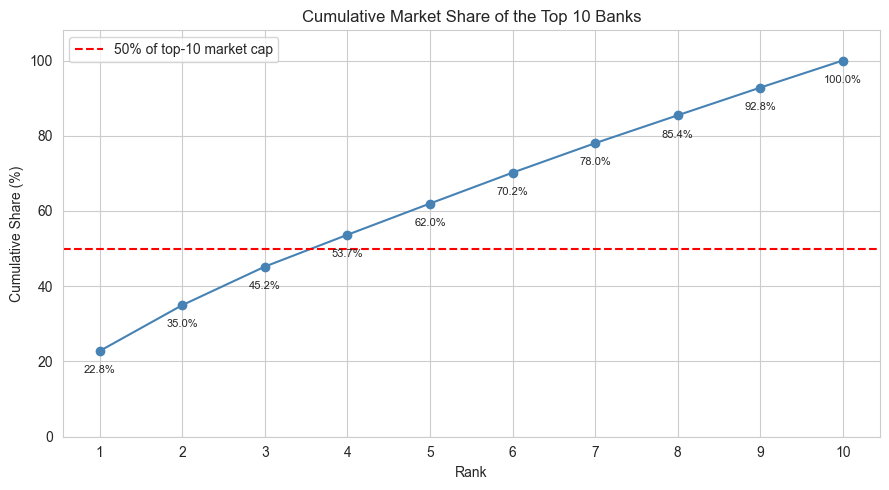

In [18]:
# Cumulative Market Share
total_cap = bank_pdf["Market_Cap_USD_Billion"].sum()
bank_pdf = bank_pdf.sort_values("Rank").reset_index(drop=True)
bank_pdf["Market_Share_Pct"] = bank_pdf["Market_Cap_USD_Billion"] / total_cap * 100
bank_pdf["Cumulative_Share_Pct"] = bank_pdf["Market_Share_Pct"].cumsum()
print(bank_pdf[["Rank", "Bank_Name", "Market_Share_Pct", "Cumulative_Share_Pct"]].round(2))

# Plot
plt.figure(figsize=(9, 5))
plt.plot(bank_pdf["Rank"], bank_pdf["Cumulative_Share_Pct"], marker="o", color="steelblue")
plt.axhline(50, color="red", linestyle="--", label="50% of top-10 market cap")
for _, row in bank_pdf.iterrows():
    plt.annotate(f"{row['Cumulative_Share_Pct']:.1f}%", (row["Rank"], row["Cumulative_Share_Pct"]),
                 textcoords="offset points", xytext=(0, -16), ha="center", fontsize=8)
plt.title("Cumulative Market Share of the Top 10 Banks")
plt.xlabel("Rank")
plt.ylabel("Cumulative Share (%)")
plt.xticks(range(1, 11))
plt.ylim(0, 108)
plt.legend()
plt.tight_layout()
plt.show()

##**3.8. Categorising Banks** <font color = red>[5 Marks]</font> <br>

Categorize banks into market capitalization ranges and analyze their distribution using a bar chart.

            Cap_Range  Banks  Total_Cap  Share_of_Total_Pct
0      Small (<$150B)      4     566.36               29.81
1  Medium ($150-200B)      4     669.02               35.21
2   Large ($200-300B)      1     231.52               12.19
3       Mega (>$300B)      1     432.92               22.79


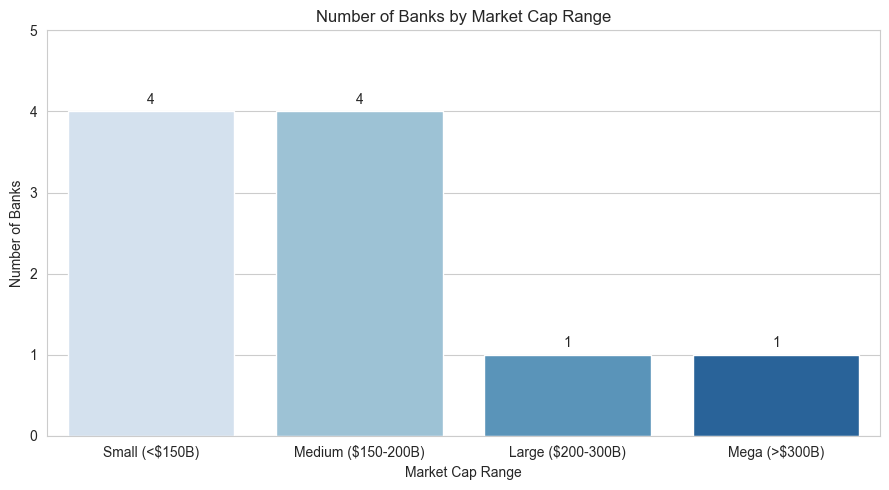

In [19]:
# Market Cap Range Distribution
# Create market cap ranges
bins = [0, 150, 200, 300, float("inf")]
labels = ["Small (<$150B)", "Medium ($150-200B)", "Large ($200-300B)", "Mega (>$300B)"]
bank_pdf["Cap_Range"] = pd.cut(bank_pdf["Market_Cap_USD_Billion"], bins=bins,
                               labels=labels, right=False)

range_summary = (bank_pdf.groupby("Cap_Range", observed=False)
                 .agg(Banks=("Bank_Name", "count"),
                      Total_Cap=("Market_Cap_USD_Billion", "sum"))
                 .reset_index())
range_summary["Share_of_Total_Pct"] = range_summary["Total_Cap"] / range_summary["Total_Cap"].sum() * 100
print(range_summary.round(2))

# Plot
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=range_summary, x="Cap_Range", y="Banks",
                 hue="Cap_Range", palette="Blues", legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title("Number of Banks by Market Cap Range")
plt.xlabel("Market Cap Range")
plt.ylabel("Number of Banks")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

##**3.9. Visualise Market Share Distribution** <font color = red>[5 Marks]</font> <br>


Calculate and display market share distribution among the top 10 banks using a pie chart.

   Rank                                Bank_Name  Market_Share_Pct
0     1                           JPMorgan Chase             22.79
1     2                          Bank of America             12.19
2     3  Industrial and Commercial Bank of China             10.24
3     4               Agricultural Bank of China              8.46
4     5                                HDFC Bank              8.31
5     6                              Wells Fargo              8.20
6     7                        HSBC Holdings PLC              7.84
7     8                           Morgan Stanley              7.41
8     9                  China Construction Bank              7.36
9    10                            Bank of China              7.20


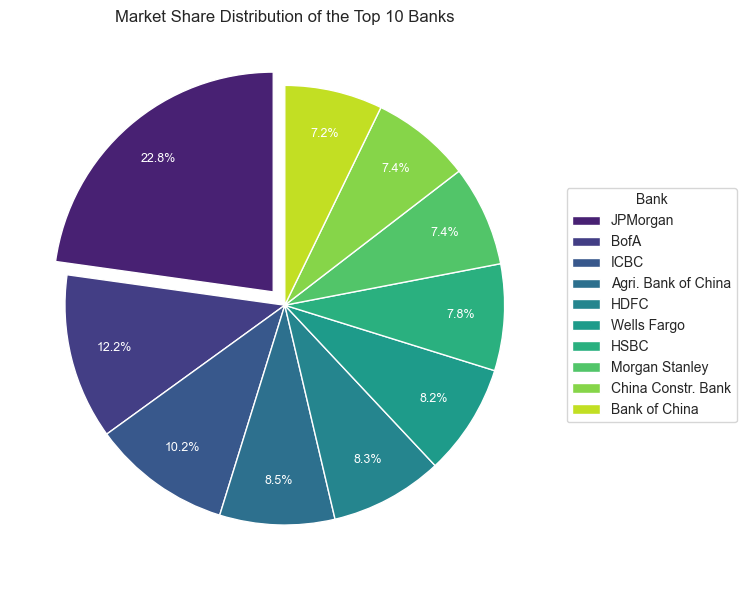

In [20]:
# Top 10 Banks Market Share
# Calculate market share percentage for top 10 banks
top10 = bank_pdf.sort_values("Market_Cap_USD_Billion", ascending=False).head(10).copy()
top10["Market_Share_Pct"] = top10["Market_Cap_USD_Billion"] / top10["Market_Cap_USD_Billion"].sum() * 100
print(top10[["Rank", "Bank_Name", "Market_Share_Pct"]].round(2))

# Plot the market share distribution
short_names = {
    "JPMorgan Chase": "JPMorgan", "Bank of America": "BofA",
    "Industrial and Commercial Bank of China": "ICBC",
    "Agricultural Bank of China": "Agri. Bank of China", "HDFC Bank": "HDFC",
    "Wells Fargo": "Wells Fargo", "HSBC Holdings PLC": "HSBC",
    "Morgan Stanley": "Morgan Stanley", "China Construction Bank": "China Constr. Bank",
    "Bank of China": "Bank of China",
}
names = top10["Bank_Name"].map(short_names)
explode = [0.08 if r == 1 else 0 for r in top10["Rank"]]   # pull JPMorgan out

fig, ax = plt.subplots(figsize=(10, 6))
wedges, _, autotexts = ax.pie(top10["Market_Cap_USD_Billion"], explode=explode,
                              autopct="%1.1f%%", startangle=90, pctdistance=0.8,
                              colors=sns.color_palette("viridis", 10),
                              wedgeprops=dict(edgecolor="white"))
for t in autotexts:
    t.set_color("white"); t.set_fontsize(9)
ax.legend(wedges, names, title="Bank", loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Market Share Distribution of the Top 10 Banks")
plt.tight_layout()
plt.show()

#**4. ETL and Querying** <font color = red>[45 marks]</font> <br>

In [21]:
#Imports & Spark Session Initialization

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, lit, round
import logging
from datetime import datetime
import sqlite3
import pandas as pd

# Initialize Spark Session
spark = SparkSession.builder \
    .appName("BankingDataAnalysis") \
    .getOrCreate()

# Logging Configuration
logfile = "code_log.txt"

In [22]:
#Logging Function

def log_progress(msg):
    timeformat = '%Y-%h-%d-%H:%M:%S'
    timestamp = datetime.now().strftime(timeformat)
    with open(logfile, 'a') as f:
        f.write(f"{timestamp} : {msg}\n")

In [23]:
# Import required functions
from pyspark.sql.functions import col, avg, sum, count, desc, asc, round, lag, dense_rank, ntile, when, first, lead, lit
from pyspark.sql.window import Window

# First, let's rename your columns to match our queries (if needed)
# Transform: convert market cap into GBP, EUR and INR using the exchange rate file
rates = {r["Currency"]: r["Rate"] for r in exchange_df.collect()}
bank_df = (df_clean
    .withColumn("Market_Cap_GBP_Billion", round(col("Market_Cap_USD_Billion") * lit(rates["GBP"]), 2))
    .withColumn("Market_Cap_EUR_Billion", round(col("Market_Cap_USD_Billion") * lit(rates["EUR"]), 2))
    .withColumn("Market_Cap_INR_Billion", round(col("Market_Cap_USD_Billion") * lit(rates["INR"]), 2)))
log_progress("Currency conversion completed (USD, GBP, EUR, INR)")
bank_df.show(truncate=False)

# Create window specifications
window_by_rank = Window.orderBy("Rank")
window_by_cap = Window.orderBy(desc("Market_Cap_USD_Billion"))
window_cumulative = Window.orderBy("Rank").rowsBetween(Window.unboundedPreceding, Window.currentRow)

# Save the transformed data as CSV and load it into SQLite
final_pdf = bank_df.toPandas()
final_pdf.to_csv("Largest_banks_transformed.csv", index=False)
log_progress("Transformed data saved to Largest_banks_transformed.csv")

conn = sqlite3.connect("Banks.db")
final_pdf.to_sql("Largest_banks", conn, if_exists="replace", index=False)
log_progress("Data loaded into SQLite table Largest_banks")
print(pd.read_sql("SELECT Rank, Bank_Name, Market_Cap_USD_Billion FROM Largest_banks LIMIT 5", conn))
conn.close()

+----+---------------------------------------+----------------------+----------------------+----------------------+----------------------+
|Rank|Bank_Name                              |Market_Cap_USD_Billion|Market_Cap_GBP_Billion|Market_Cap_EUR_Billion|Market_Cap_INR_Billion|
+----+---------------------------------------+----------------------+----------------------+----------------------+----------------------+
|1   |JPMorgan Chase                         |432.92                |346.34                |402.62                |35910.71              |
|2   |Bank of America                        |231.52                |185.22                |215.31                |19204.58              |
|3   |Industrial and Commercial Bank of China|194.56                |155.65                |180.94                |16138.75              |
|4   |Agricultural Bank of China             |160.68                |128.54                |149.43                |13328.41              |
|5   |HDFC Bank            

##**4.1. Market Capitalization Analysis** <font color = red>[3 marks]</font> <br>

Q: Perform Advanced Market Capitalization Analysis with Growth Metrics

In [24]:
# Query: Advanced Market Cap Analysis with Growth Metrics
w_all = Window.orderBy("Rank").rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)

growth_df = (bank_df
    .withColumn("Prev_Bank_Cap", lag("Market_Cap_USD_Billion", 1).over(window_by_rank))
    .withColumn("Next_Bank_Cap", lead("Market_Cap_USD_Billion", 1).over(window_by_rank))
    .withColumn("Diff_vs_Bank_Above", round(col("Market_Cap_USD_Billion") - col("Prev_Bank_Cap"), 2))
    .withColumn("Pct_Change_vs_Above", round((col("Market_Cap_USD_Billion") - col("Prev_Bank_Cap")) / col("Prev_Bank_Cap") * 100, 2))
    .withColumn("Premium_over_Next_Pct", round((col("Market_Cap_USD_Billion") - col("Next_Bank_Cap")) / col("Next_Bank_Cap") * 100, 2))
    .withColumn("Cumulative_Cap_USD", round(sum("Market_Cap_USD_Billion").over(window_cumulative), 2))
    .withColumn("Pct_of_Average", round(col("Market_Cap_USD_Billion") / avg("Market_Cap_USD_Billion").over(w_all) * 100, 1)))

growth_df.select("Rank", "Bank_Name", "Market_Cap_USD_Billion", "Diff_vs_Bank_Above",
                 "Pct_Change_vs_Above", "Premium_over_Next_Pct",
                 "Cumulative_Cap_USD", "Pct_of_Average").show(truncate=False)
log_progress("4.1 Advanced market cap analysis with growth metrics completed")

+----+---------------------------------------+----------------------+------------------+-------------------+---------------------+------------------+--------------+
|Rank|Bank_Name                              |Market_Cap_USD_Billion|Diff_vs_Bank_Above|Pct_Change_vs_Above|Premium_over_Next_Pct|Cumulative_Cap_USD|Pct_of_Average|
+----+---------------------------------------+----------------------+------------------+-------------------+---------------------+------------------+--------------+
|1   |JPMorgan Chase                         |432.92                |NULL              |NULL               |86.99                |432.92            |227.9         |
|2   |Bank of America                        |231.52                |-201.4            |-46.52             |19.0                 |664.44            |121.9         |
|3   |Industrial and Commercial Bank of China|194.56                |-36.96            |-15.96             |21.09                |859.0             |102.4         |
|4   |Agri

##4.2.**Market Concentration Analysis** <font color = red>[6 marks]</font> <br>

Q: Analyze Market Concentration and Categorize Banks Based on Market Share Tiers

In [25]:
# Market Concentration Analysis
w_total = Window.orderBy("Rank").rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)

concentration_df = (bank_df
    .withColumn("Market_Share_Pct", round(col("Market_Cap_USD_Billion") / sum("Market_Cap_USD_Billion").over(w_total) * 100, 2))
    .withColumn("Share_Tier",
                when(col("Market_Share_Pct") >= 15, "Tier 1 - Dominant")
                .when(col("Market_Share_Pct") >= 10, "Tier 2 - Major")
                .when(col("Market_Share_Pct") >= 8, "Tier 3 - Mid-tier")
                .otherwise("Tier 4 - Challenger")))

concentration_df.select("Rank", "Bank_Name", "Market_Share_Pct", "Share_Tier").show(truncate=False)

# Tier summary
concentration_df.groupBy("Share_Tier").agg(
    count("*").alias("Banks"),
    round(sum("Market_Share_Pct"), 2).alias("Combined_Share_Pct")
).orderBy("Share_Tier").show(truncate=False)

# Concentration measures (CR1, CR3, CR5 and HHI)
share_pdf = concentration_df.select("Rank", "Market_Share_Pct").toPandas().sort_values("Rank")
shares = share_pdf["Market_Share_Pct"]
print("CR1 :", shares.head(1).sum().round(2))
print("CR3 :", shares.head(3).sum().round(2))
print("CR5 :", shares.head(5).sum().round(2))
print("HHI :", (shares ** 2).sum().round(1))
log_progress("4.2 Market concentration analysis completed")

+----+---------------------------------------+----------------+-------------------+
|Rank|Bank_Name                              |Market_Share_Pct|Share_Tier         |
+----+---------------------------------------+----------------+-------------------+
|1   |JPMorgan Chase                         |22.79           |Tier 1 - Dominant  |
|2   |Bank of America                        |12.19           |Tier 2 - Major     |
|3   |Industrial and Commercial Bank of China|10.24           |Tier 2 - Major     |
|4   |Agricultural Bank of China             |8.46            |Tier 3 - Mid-tier  |
|5   |HDFC Bank                              |8.31            |Tier 3 - Mid-tier  |
|6   |Wells Fargo                            |8.2             |Tier 3 - Mid-tier  |
|7   |HSBC Holdings PLC                      |7.84            |Tier 4 - Challenger|
|8   |Morgan Stanley                         |7.41            |Tier 4 - Challenger|
|9   |China Construction Bank                |7.36            |Tier 4 - Chal

##**4.3. Market Capitalization Distribution** <font color = red>[6 marks]</font> <br>

Q: Examine Statistical Distribution of Market Capitalization Using Quartile Analysis

In [26]:
# Import required functions
from pyspark.sql.functions import (col, avg, sum, count, desc, asc, round, lag,
                                 dense_rank, ntile, when, first, lead, min, max, lit)
from pyspark.sql.window import Window

# Query 3: Statistical Distribution Analysis

# Overall descriptive statistics and quartile boundaries
bank_df.selectExpr(
    "count(*) AS Banks",
    "round(avg(Market_Cap_USD_Billion), 2) AS Mean",
    "round(stddev(Market_Cap_USD_Billion), 2) AS Std_Dev",
    "min(Market_Cap_USD_Billion) AS Minimum",
    "round(percentile(Market_Cap_USD_Billion, 0.25), 2) AS Q1",
    "round(percentile(Market_Cap_USD_Billion, 0.5), 2) AS Median",
    "round(percentile(Market_Cap_USD_Billion, 0.75), 2) AS Q3",
    "max(Market_Cap_USD_Billion) AS Maximum",
    "round(percentile(Market_Cap_USD_Billion, 0.75) - percentile(Market_Cap_USD_Billion, 0.25), 2) AS IQR"
).show(truncate=False)

# Assign each bank to a quartile group (1 = largest banks)
quartile_df = bank_df.withColumn("Quartile_Group", ntile(4).over(window_by_cap))

quartile_df.groupBy("Quartile_Group").agg(
    count("*").alias("Banks"),
    min("Market_Cap_USD_Billion").alias("Min_Cap"),
    max("Market_Cap_USD_Billion").alias("Max_Cap"),
    round(avg("Market_Cap_USD_Billion"), 2).alias("Avg_Cap"),
    round(sum("Market_Cap_USD_Billion"), 2).alias("Total_Cap")
).orderBy("Quartile_Group").show(truncate=False)

quartile_df.select("Rank", "Bank_Name", "Market_Cap_USD_Billion", "Quartile_Group").orderBy("Rank").show(truncate=False)
log_progress("4.3 Quartile analysis completed")

+-----+------+-------+-------+------+------+------+-------+-----+
|Banks|Mean  |Std_Dev|Minimum|Q1    |Median|Q3    |Maximum|IQR  |
+-----+------+-------+-------+------+------+------+-------+-----+
|10   |189.98|90.22  |136.81 |142.85|156.89|186.09|432.92 |43.24|
+-----+------+-------+-------+------+------+------+-------+-----+

+--------------+-----+-------+-------+-------+---------+
|Quartile_Group|Banks|Min_Cap|Max_Cap|Avg_Cap|Total_Cap|
+--------------+-----+-------+-------+-------+---------+
|1             |3    |194.56 |432.92 |286.33 |859.0    |
|2             |3    |155.87 |160.68 |158.15 |474.46   |
|3             |2    |140.83 |148.9  |144.87 |289.73   |
|4             |2    |136.81 |139.82 |138.32 |276.63   |
+--------------+-----+-------+-------+-------+---------+

+----+---------------------------------------+----------------------+--------------+
|Rank|Bank_Name                              |Market_Cap_USD_Billion|Quartile_Group|
+----+------------------------------------

##**4.4. Comparative Size Analysis** <font color = red>[6 marks]</font> <br>

Q: Conduct Comparative Size Analysis to Classify Banks by Relative Market Size

In [27]:
# Comparative Size Analysis
w_full = Window.orderBy("Rank").rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)

# Median market cap (exact) as the reference point for a "typical" bank
median_cap = bank_df.selectExpr("percentile(Market_Cap_USD_Billion, 0.5)").first()[0]

size_df = (bank_df
    .withColumn("Ratio_to_Median", round(col("Market_Cap_USD_Billion") / lit(median_cap), 2))
    .withColumn("Ratio_to_Smallest", round(col("Market_Cap_USD_Billion") / min("Market_Cap_USD_Billion").over(w_full), 2))
    .withColumn("Pct_of_Largest", round(col("Market_Cap_USD_Billion") / max("Market_Cap_USD_Billion").over(w_full) * 100, 1))
    .withColumn("Size_Class",
                when(col("Market_Cap_USD_Billion") >= 2.0 * lit(median_cap), "Giant (>=2x median)")
                .when(col("Market_Cap_USD_Billion") >= 1.2 * lit(median_cap), "Large (1.2-2x median)")
                .when(col("Market_Cap_USD_Billion") >= 0.92 * lit(median_cap), "Mid-size (0.92-1.2x median)")
                .otherwise("Smaller (<0.92x median)")))

size_df.select("Rank", "Bank_Name", "Market_Cap_USD_Billion", "Ratio_to_Median",
               "Ratio_to_Smallest", "Pct_of_Largest", "Size_Class").show(truncate=False)

size_df.groupBy("Size_Class").agg(count("*").alias("Banks"),
                                  round(sum("Market_Cap_USD_Billion"), 2).alias("Total_Cap")
).orderBy(desc("Total_Cap")).show(truncate=False)
log_progress("4.4 Comparative size analysis completed")

+----+---------------------------------------+----------------------+---------------+-----------------+--------------+---------------------------+
|Rank|Bank_Name                              |Market_Cap_USD_Billion|Ratio_to_Median|Ratio_to_Smallest|Pct_of_Largest|Size_Class                 |
+----+---------------------------------------+----------------------+---------------+-----------------+--------------+---------------------------+
|1   |JPMorgan Chase                         |432.92                |2.76           |3.16             |100.0         |Giant (>=2x median)        |
|2   |Bank of America                        |231.52                |1.48           |1.69             |53.5          |Large (1.2-2x median)      |
|3   |Industrial and Commercial Bank of China|194.56                |1.24           |1.42             |44.9          |Large (1.2-2x median)      |
|4   |Agricultural Bank of China             |160.68                |1.02           |1.17             |37.1          |

##**4.5. Market Growth Analysis** <font color = red>[6 marks]</font> <br>

Q: Evaluate Market Growth and Identify Gaps Between Consecutive Banks

In [28]:
# Growth and Gap Analysis
w_gap = Window.orderBy("Rank")
w_leader = Window.orderBy("Rank").rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)

gap_df = (bank_df
    .withColumn("Cap_Next_Bank", lead("Market_Cap_USD_Billion", 1).over(w_gap))
    .withColumn("Cap_Bank_Above", lag("Market_Cap_USD_Billion", 1).over(w_gap))
    .withColumn("Gap_to_Next_USD", round(col("Market_Cap_USD_Billion") - col("Cap_Next_Bank"), 2))
    .withColumn("Gap_to_Next_Pct", round((col("Market_Cap_USD_Billion") - col("Cap_Next_Bank")) / col("Cap_Next_Bank") * 100, 2))
    .withColumn("Gap_to_Leader_USD", round(max("Market_Cap_USD_Billion").over(w_leader) - col("Market_Cap_USD_Billion"), 2))
    .withColumn("Growth_Needed_to_Move_Up_Pct", round((col("Cap_Bank_Above") - col("Market_Cap_USD_Billion")) / col("Market_Cap_USD_Billion") * 100, 2))
    .withColumn("Gap_Type",
                when(col("Gap_to_Next_Pct").isNull(), "Last in top 10")
                .when(col("Gap_to_Next_Pct") >= 10, "Large gap (>=10%)")
                .when(col("Gap_to_Next_Pct") >= 3, "Moderate gap (3-10%)")
                .otherwise("Tight race (<3%)")))

gap_df.select("Rank", "Bank_Name", "Gap_to_Next_USD", "Gap_to_Next_Pct",
              "Gap_to_Leader_USD", "Growth_Needed_to_Move_Up_Pct", "Gap_Type").show(truncate=False)

# Largest gaps between consecutive banks
print("Three largest gaps between consecutive banks:")
gap_df.filter(col("Gap_to_Next_USD").isNotNull()).orderBy(desc("Gap_to_Next_USD")) \
      .select("Rank", "Bank_Name", "Gap_to_Next_USD", "Gap_to_Next_Pct").show(3, truncate=False)
log_progress("4.5 Growth and gap analysis completed")

+----+---------------------------------------+---------------+---------------+-----------------+----------------------------+--------------------+
|Rank|Bank_Name                              |Gap_to_Next_USD|Gap_to_Next_Pct|Gap_to_Leader_USD|Growth_Needed_to_Move_Up_Pct|Gap_Type            |
+----+---------------------------------------+---------------+---------------+-----------------+----------------------------+--------------------+
|1   |JPMorgan Chase                         |201.4          |86.99          |0.0              |NULL                        |Large gap (>=10%)   |
|2   |Bank of America                        |36.96          |19.0           |201.4            |86.99                       |Large gap (>=10%)   |
|3   |Industrial and Commercial Bank of China|33.88          |21.09          |238.36           |19.0                        |Large gap (>=10%)   |
|4   |Agricultural Bank of China             |2.77           |1.75           |272.24           |21.09                 

In [ ]:
# --- Supplementary view: asset-rank movement from S&P Global (Global.xlsx) ---
g = pd.read_excel("D:/downloads/Global.xlsx", header=2).iloc[:, [1, 2, 4, 7]]
g.columns = ["Asset_Rank_Now", "Asset_Rank_Prev", "bank", "Total_Assets_USD_B"]
g = g[pd.to_numeric(g["Asset_Rank_Now"], errors="coerce").notna()].copy()
g["Asset_Rank_Now"] = g["Asset_Rank_Now"].astype(int)
g["Asset_Rank_Prev"] = pd.to_numeric(g["Asset_Rank_Prev"], errors="coerce")   # '-' = new entrant
g["Rank_Change"] = g["Asset_Rank_Prev"] - g["Asset_Rank_Now"]                 # + = moved up
g["bank_clean"] = (g["bank"].str.replace(r"\s*\(.*?\)", "", regex=True)
                            .str.replace(r"[\d\*]+$", "", regex=True).str.strip())

name_map = {
    "JPMorgan Chase": "JPMorgan Chase & Co.",
    "Bank of America": "Bank of America Corp.",
    "Industrial and Commercial Bank of China": "Industrial and Commercial Bank of China Ltd.",
    "Agricultural Bank of China": "Agricultural Bank of China Ltd.",
    "HDFC Bank": "HDFC Bank",
    "Wells Fargo": "Wells Fargo & Co.",
    "HSBC Holdings PLC": "HSBC Holdings PLC",
    "Morgan Stanley": "Morgan Stanley",
    "China Construction Bank": "China Construction Bank Corp.",
    "Bank of China": "Bank of China Ltd.",
}
sup = bank_pdf[["Rank", "Bank_Name", "Market_Cap_USD_Billion"]].copy()
sup["Global_Name"] = sup["Bank_Name"].map(name_map)
sup = sup.merge(g[["bank_clean", "Asset_Rank_Now", "Asset_Rank_Prev", "Rank_Change", "Total_Assets_USD_B"]],
                left_on="Global_Name", right_on="bank_clean", how="left")
sup["Cap_to_Assets_Pct"] = (sup["Market_Cap_USD_Billion"] / sup["Total_Assets_USD_B"] * 100).round(2)
sup["Total_Assets_USD_B"] = sup["Total_Assets_USD_B"].round(2)
print(sup[["Rank", "Bank_Name", "Asset_Rank_Now", "Asset_Rank_Prev", "Rank_Change",
           "Total_Assets_USD_B", "Cap_to_Assets_Pct"]].to_string(index=False))

##**4.6. Market Dominance Analysis** <font color = red>[6 marks]</font> <br>

Q: Assess Market Dominance by Measuring Cumulative Share and Dominance Score

In [ ]:
# Market Dominance Analysis
from pyspark.sql.functions import coalesce

w_whole = Window.orderBy("Rank").rowsBetween(Window.unboundedPreceding, Window.unboundedFollowing)

dominance_df = (bank_df
    .withColumn("Market_Share_Pct", col("Market_Cap_USD_Billion") / sum("Market_Cap_USD_Billion").over(w_whole) * 100)
    .withColumn("Cumulative_Share_Pct", sum("Market_Share_Pct").over(window_cumulative))
    # lead over the next-ranked bank (last bank has no rival below -> 1.0)
    .withColumn("Lead_Ratio", coalesce(col("Market_Cap_USD_Billion") / lead("Market_Cap_USD_Billion", 1).over(window_by_rank), lit(1.0)))
    # dominance score = share of total x lead over next bank
    .withColumn("Dominance_Score", col("Market_Share_Pct") * col("Lead_Ratio"))
    .withColumn("Dominance_Level",
                when(col("Dominance_Score") >= 20, "Market leader")
                .when(col("Dominance_Score") >= 10, "Strong")
                .otherwise("Competitive")))

dominance_df.select("Rank", "Bank_Name",
                    round("Market_Share_Pct", 2).alias("Market_Share_Pct"),
                    round("Cumulative_Share_Pct", 2).alias("Cumulative_Share_Pct"),
                    round("Lead_Ratio", 3).alias("Lead_Ratio"),
                    round("Dominance_Score", 2).alias("Dominance_Score"),
                    "Dominance_Level").show(truncate=False)

# How many banks does it take to reach 50% and 80% of top-10 market cap?
for target in (50, 80):
    n = dominance_df.filter(col("Cumulative_Share_Pct") >= target).agg(min("Rank")).first()[0]
    print(f"{n} banks are needed to reach {target}% of the top-10 market cap")
log_progress("4.6 Market dominance analysis completed")

##**4.7. Segment-Wise Bank Analysis** <font color = red>[6 marks]</font> <br>

Q: Analyze Segment-Wise Bank Performance Based on Market Capitalization Ranges

In [ ]:
# Segment Performance Analysis
segment_df = bank_df.withColumn("Segment",
    when(col("Market_Cap_USD_Billion") < 150, "1 - Small (<$150B)")
    .when(col("Market_Cap_USD_Billion") < 200, "2 - Medium ($150-200B)")
    .when(col("Market_Cap_USD_Billion") < 300, "3 - Large ($200-300B)")
    .otherwise("4 - Mega (>$300B)"))

segment_summary = (segment_df.groupBy("Segment").agg(
        count("*").alias("Banks"),
        round(sum("Market_Cap_USD_Billion"), 2).alias("Total_Cap_USD"),
        round(avg("Market_Cap_USD_Billion"), 2).alias("Avg_Cap_USD"),
        min("Market_Cap_USD_Billion").alias("Min_Cap_USD"),
        max("Market_Cap_USD_Billion").alias("Max_Cap_USD"),
        round(avg("Market_Cap_INR_Billion"), 2).alias("Avg_Cap_INR"))
    .withColumn("Share_of_Total_Pct",
                round(col("Total_Cap_USD") / sum("Total_Cap_USD").over(Window.partitionBy()) * 100, 2))
    .orderBy("Segment"))
segment_summary.show(truncate=False)

# Which banks sit in each segment
members = (segment_df.toPandas().sort_values("Rank")
           .groupby("Segment")["Bank_Name"].apply(lambda s: ", ".join(s)))
for seg, banks in members.items():
    print(f"{seg}: {banks}")
log_progress("4.7 Segment performance analysis completed")

##**4.8. Performance Dashboard** <font color = red>[6 marks]</font> <br>

Q: Generate a Comprehensive Performance Dashboard for Bank Rankings and Metrics

In [ ]:
# Comprehensive Performance Dashboard
# Combine the metrics from 4.2-4.7 into one table (joined on Rank)
dash = (bank_df.toPandas()
        .merge(concentration_df.select("Rank", "Market_Share_Pct", "Share_Tier").toPandas(), on="Rank")
        .merge(size_df.select("Rank", "Size_Class").toPandas(), on="Rank")
        .merge(dominance_df.select("Rank", "Cumulative_Share_Pct", "Dominance_Score", "Dominance_Level").toPandas(), on="Rank")
        .merge(gap_df.select("Rank", "Gap_to_Next_Pct", "Gap_Type").toPandas(), on="Rank")
        .merge(segment_df.select("Rank", "Segment").toPandas(), on="Rank")
        .sort_values("Rank").reset_index(drop=True))
dash["Cumulative_Share_Pct"] = dash["Cumulative_Share_Pct"].round(2)
dash["Dominance_Score"] = dash["Dominance_Score"].round(2)

short = {"JPMorgan Chase": "JPMorgan", "Bank of America": "BofA",
         "Industrial and Commercial Bank of China": "ICBC",
         "Agricultural Bank of China": "Agri. Bank of China", "HDFC Bank": "HDFC",
         "Wells Fargo": "Wells Fargo", "HSBC Holdings PLC": "HSBC",
         "Morgan Stanley": "Morgan Stanley", "China Construction Bank": "China Constr. Bank",
         "Bank of China": "Bank of China"}
dash["Short_Name"] = dash["Bank_Name"].map(short)

# Key metrics
print("KEY METRICS")
print(f"Total top-10 market cap : ${dash['Market_Cap_USD_Billion'].sum():,.2f}B | "
      f"£{dash['Market_Cap_GBP_Billion'].sum():,.2f}B | €{dash['Market_Cap_EUR_Billion'].sum():,.2f}B | "
      f"₹{dash['Market_Cap_INR_Billion'].sum():,.2f}B")
print(f"Leader                  : {dash.loc[0, 'Bank_Name']} ({dash.loc[0, 'Market_Share_Pct']:.2f}% share)")
print(f"Top-3 share (CR3)       : {dash['Market_Share_Pct'].head(3).sum():.2f}%")
print(f"Average / median cap    : ${dash['Market_Cap_USD_Billion'].mean():,.2f}B / ${dash['Market_Cap_USD_Billion'].median():,.2f}B")

# Dashboard figure (2 x 2)
tier_colors = {"Tier 1 - Dominant": "#1b4965", "Tier 2 - Major": "#5fa8d3",
               "Tier 3 - Mid-tier": "#f4a259", "Tier 4 - Challenger": "#bcbcbc"}
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Top 10 Global Banks - Performance Dashboard", fontsize=16, fontweight="bold")

# 1) Market cap by bank, coloured by share tier
ax = axes[0, 0]
ax.barh(dash["Short_Name"], dash["Market_Cap_USD_Billion"], color=dash["Share_Tier"].map(tier_colors))
ax.invert_yaxis()
for i, v in enumerate(dash["Market_Cap_USD_Billion"]):
    ax.text(v + 4, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlim(0, dash["Market_Cap_USD_Billion"].max() * 1.15)
ax.set_title("Market Cap (US$ Billion) by Share Tier")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in tier_colors.values()],
          labels=list(tier_colors.keys()), loc="lower right", fontsize=8)

# 2) Cumulative market share
ax = axes[0, 1]
ax.plot(dash["Rank"], dash["Cumulative_Share_Pct"], marker="o", color="steelblue")
ax.axhline(50, color="red", linestyle="--", label="50%")
ax.axhline(80, color="green", linestyle="--", label="80%")
ax.set_xticks(range(1, 11)); ax.set_ylim(0, 108)
ax.set_title("Cumulative Market Share (%)"); ax.set_xlabel("Rank"); ax.legend()

# 3) Dominance score
ax = axes[1, 0]
ax.bar(dash["Short_Name"], dash["Dominance_Score"], color="#5fa8d3")
ax.axhline(20, color="red", linestyle="--", label="Market leader (20)")
ax.axhline(10, color="orange", linestyle="--", label="Strong (10)")
ax.set_title("Dominance Score"); ax.tick_params(axis="x", rotation=60); ax.legend()

# 4) Total market cap by size segment
ax = axes[1, 1]
seg = dash.groupby("Segment").agg(Banks=("Bank_Name", "count"),
                                  Total=("Market_Cap_USD_Billion", "sum")).reset_index()
bars = ax.bar(seg["Segment"].str.replace(r"^\d - ", "", regex=True), seg["Total"], color="#9ccf9c")
for b, n in zip(bars, seg["Banks"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 8, f"{n} bank(s)", ha="center", fontsize=9)
ax.set_ylim(0, seg["Total"].max() * 1.15)
ax.set_title("Total Market Cap by Size Segment (US$ Billion)"); ax.tick_params(axis="x", rotation=15)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("bank_dashboard.png", dpi=150)
plt.show()

# Dashboard table + export for the visualization step (Section 5)
display_cols = ["Rank", "Bank_Name", "Market_Cap_USD_Billion", "Market_Share_Pct", "Cumulative_Share_Pct",
                "Share_Tier", "Size_Class", "Dominance_Score", "Gap_Type", "Segment"]
print(dash[display_cols].to_string(index=False))
dash.drop(columns="Short_Name").to_csv("bank_dashboard_data.csv", index=False)
log_progress("4.8 Performance dashboard created")

#5. Visualization Integration

In [ ]:
# Visualization Setup Section
import os

# 1. Prepare data for visualization platforms
def prepare_viz_data():
    cols = ["Rank", "Bank_Name", "Market_Cap_USD_Billion", "Market_Cap_GBP_Billion",
            "Market_Cap_EUR_Billion", "Market_Cap_INR_Billion", "Market_Share_Pct",
            "Cumulative_Share_Pct", "Share_Tier", "Size_Class", "Dominance_Score",
            "Dominance_Level", "Gap_to_Next_Pct", "Gap_Type", "Segment"]
    wide = dash[cols].copy()
    wide["Market_Share_Pct"] = wide["Market_Share_Pct"].round(2)
    wide["Gap_to_Next_Pct"] = wide["Gap_to_Next_Pct"].round(2)
    wide.to_csv("bank_viz_data.csv", index=False)

    # Long format: one row per bank per currency (easier for currency filters in BI tools)
    long = wide.melt(id_vars=["Rank", "Bank_Name"],
                     value_vars=["Market_Cap_USD_Billion", "Market_Cap_GBP_Billion",
                                 "Market_Cap_EUR_Billion", "Market_Cap_INR_Billion"],
                     var_name="Currency", value_name="Market_Cap_Billion")
    long["Currency"] = long["Currency"].str.extract(r"_(USD|GBP|EUR|INR)_")[0]
    long.to_csv("bank_viz_currency_long.csv", index=False)
    return os.path.abspath("bank_viz_data.csv"), os.path.abspath("bank_viz_currency_long.csv")

# 2. Generate Tableau connection instructions
def tableau_instructions(wide_path, long_path):
    return f"""TABLEAU
1. Open Tableau > Connect > To a File > Text file > select: {wide_path}
2. Drag Bank_Name to Rows and Market_Cap_USD_Billion to Columns; sort descending.
3. Colour by Share_Tier; add Market_Share_Pct to the tooltip.
4. Add a second sheet from: {long_path} (filter on Currency) for cross-currency views.
5. Refresh: overwrite the CSV by re-running this notebook, then Data > Refresh Data Source.
6. Cloud option: load the CSV to an S3 bucket and query it through Amazon Athena (Tableau's Athena connector)."""

# 3. Generate Power BI connection instructions
def powerbi_instructions(wide_path, long_path):
    return f"""POWER BI
1. Home > Get Data > Text/CSV > select: {wide_path} > Load.
2. Insert a clustered bar chart: Axis = Bank_Name, Values = Market_Cap_USD_Billion.
3. Add a donut chart (Market_Share_Pct by Bank_Name) and a slicer on Segment.
4. Import {long_path} and add a Currency slicer to switch USD / GBP / EUR / INR.
5. Refresh: re-run this notebook to overwrite the CSV, then click Refresh in Power BI.
6. Cloud option: store the CSV in S3 and connect through Amazon Athena (verify the connector available in your Power BI version)."""

# 4. Execute visualization setup
wide_path, long_path = prepare_viz_data()
print("Files prepared:\n ", wide_path, "\n ", long_path)
print()
print(tableau_instructions(wide_path, long_path))
print()
print(powerbi_instructions(wide_path, long_path))
log_progress("Section 5 visualization data prepared (bank_viz_data.csv, bank_viz_currency_long.csv)")

# 5. Sample Dashboard Layout (Documentation)
layout = """
SAMPLE DASHBOARD LAYOUT
+-----------------------------------------------------------+
| KPI cards: Total Market Cap | Leader | CR3 | HHI          |
+-----------------------------+-----------------------------+
| Bar: Market cap by bank     | Line: Cumulative share      |
| (coloured by Share_Tier)    | (50% / 80% reference lines) |
+-----------------------------+-----------------------------+
| Bar: Dominance score        | Bar: Cap by size segment    |
+-----------------------------+-----------------------------+
| Slicers: Currency | Segment | Share_Tier                  |
+-----------------------------------------------------------+
"""
print(layout)